In [8]:
import os
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from pydantic import BaseModel
from langgraph.types import interrupt

In [9]:
load_dotenv()  # Load environment variables from .env file

True

In [10]:
generate_model = ChatOpenAI(
    model=os.getenv("GEMINI_AI_MODEL", "gemini-3.5-flash-lite"),
    api_key=os.getenv("GEMINI_API_KEY"),
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    temperature=0
)

evaluate_model = ChatOpenAI(
    model=os.getenv("GEMINI_EVALUATE_MODEL", "gemini-3-flash-lite"),
    api_key=os.getenv("GEMINI_API_KEY"),
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    temperature=0
)

optimize_model = ChatOpenAI(
    model=os.getenv("GEMINI_OPTIMIZE_MODEL", "gemini-3.1-flash-lite"),
    api_key=os.getenv("GEMINI_API_KEY"),
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    temperature=0
)

In [11]:
class TweetState(TypedDict):
    topic: str
    tweet: str
    score: int
    feedback: Literal["approved", "rejected"]
    iteration: int
    human_approved: Literal["approved", "rejected"]

class EvaluationState(BaseModel):
    score: int
    feedback: Literal["approved", "rejected"]

structured_evaluate_model = evaluate_model.with_structured_output(EvaluationState)        

In [12]:
def genrate_tweet(state: TweetState):
    prompt = f"""
You are a professional X (Twitter) content strategist and copywriter.

Create a high-quality tweet based on the following topic.

Topic: {state['topic']}

Requirements:
- Start with a compelling hook.
- Communicate one clear, valuable idea.
- Use natural, professional, human-like language.
- Make the tweet informative and engaging.
- Avoid clichés, filler, clickbait, and unnecessary emojis.
- Use a maximum of 2 relevant hashtags when appropriate.
- Never invent statistics, facts, or personal experiences.
- Keep the tweet within 280 characters, including spaces.
- Do not include explanations or multiple alternatives.

Return only the tweet, ready to publish on X.
"""
    res = generate_model.invoke(prompt).content
    return { 'tweet': res, "iteration": 0 }

def evaluate_tweet(state: TweetState):
    prompt = f"""
You are a strict professional X (Twitter) content evaluator.

Evaluate the following tweet based on the original topic.

Original topic:
{state['topic']}

Tweet:
{state['tweet']}

Evaluate these criteria:
1. Relevance to the topic.
2. Strength of the opening hook.
3. Clarity and readability.
4. Usefulness and originality.
5. Engagement potential.
6. Professionalism and natural language.
7. Factual accuracy.
8. Compliance with the 280-character limit.

Scoring:
- Give an overall integer score from 1 to 10.
- 9-10: Excellent; ready for publication.
- 7-8: Good, but improvements may be needed.
- 4-6: Significant improvements required.
- 1-3: Poor, misleading, irrelevant, or unclear.

Feedback:
- Explain the most important weaknesses.
- Provide specific, actionable improvements.
- If the tweet is excellent, clearly state that no major changes are needed.
- Penalize fabricated claims and misleading content.
- Treat exceeding 280 characters as a significant failure.
- Be objective and do not give high scores without justification.

Return the result using the required structured output:
- score: integer from 1 to 10
- feedback: concise, actionable evaluation
"""
    res = structured_evaluate_model.invoke(prompt)
    return { 'score': res.score, 'feedback': res.feedback }

def optimize_tweet(state: TweetState):
    prompt = f"""
You are an expert X (Twitter) copywriter specializing in tweet optimization.

Improve the current tweet using the evaluator's feedback.

Original topic:
{state['topic']}

Current tweet:
{state['tweet']}

Evaluation score:
{state['score']}/10

Evaluator feedback:
{state['feedback']}

Requirements:
- Address the evaluator's identified weaknesses.
- Improve the hook, clarity, originality, and engagement.
- Preserve the original topic and intended meaning.
- Use concise, natural, professional language.
- Remove unnecessary words and repetition.
- Use a maximum of 2 relevant hashtags when appropriate.
- Never invent facts, statistics, sources, or personal experiences.
- Keep the final tweet within 280 characters, including spaces.
- Make meaningful improvements rather than superficial changes.
- Return only the optimized tweet.
- Do not include explanations, scores, or multiple alternatives.
"""
    res = generate_model.invoke(prompt).content
    return { 'tweet': res, "iteration": state["iteration"] + 1}

def route_tweet(state: TweetState):
    if state['feedback'] == "approved" or state['iteration'] >= 3:
        return  "approved" 
    else: 
        return "rejected"

def route_human_approval(state: TweetState):
    if state["human_approved"]:
        return "approved"

    return "rejected"    

def human_approval(state: TweetState):
    decision = interrupt({
        "message": "Review the final tweet before publishing.",
        "tweet": state["tweet"],
        "score": state["score"],
        "feedback": state["feedback"],
    })

    return {"human_approved": decision["approved"]}    
    

In [13]:
graph = StateGraph(TweetState)

graph.add_node("genrate_tweet",genrate_tweet)
graph.add_node("evaluate_tweet",evaluate_tweet)
graph.add_node("optimize_tweet",optimize_tweet)
graph.add_node("human_approval", human_approval)

graph.add_edge(START,"genrate_tweet")
graph.add_edge("genrate_tweet","evaluate_tweet")
graph.add_conditional_edges("evaluate_tweet",route_tweet,{
    'approved': "human_approval",
    'rejected': "optimize_tweet"
})
graph.add_edge("optimize_tweet","evaluate_tweet")
graph.add_conditional_edges(
    "human_approval",
    route_human_approval,
    {
        "approved": END,
        "rejected": END,
    },
)

workflow = graph.compile()

In [14]:
inital_state = {"topic": "Indian Politics"}
output = workflow.invoke(inital_state)
print(output["__interrupt__"])

OpenAIModelNotFoundError: Error code: 404 - [{'error': {'code': 404, 'message': 'models/gemini-3.0-flash-lite is not found for API version v1main, or is not supported for generateContent. Call ModelService.ListModels to see the list of available models and their supported methods.', 'status': 'NOT_FOUND'}}]

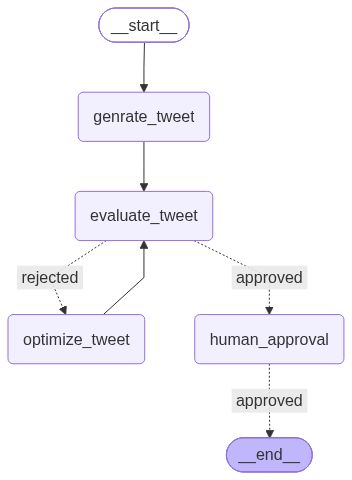

In [ ]:
from IPython.display import display, Image

display(
    Image(workflow.get_graph().draw_mermaid_png())
)